# Profils de consommation hebdomadaires — Bressoux

Construction de **33 profils-types hebdomadaires** de puissance active (kW) à partir
des 33 compteurs (EAN) retenus, en vue de leur extrapolation stochastique vers les 
bus du powerflow PandaPower (`power_flow.ipynb`).

**Principe :** aucun compteur n'est exclu, aucun profil n'est « corrigé ». Les logements
peu ou pas occupés produisent des profils bas — c'est voulu, cela reflète le parc réel.
La seule opération de qualité est l'omission automatique des `NaN` lors du moyennage.

**Sortie :** une matrice `weekly_bank` de forme (33, 672) — 7 jours × 96 pas de 15 min —
en **puissance active [MW]**. La tension n'intervient pas ici : c'est une *sortie* du
powerflow, pas une entrée.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# --- Import des données (même méthode que analyze_Bressoux_data.ipynb) ---
df = pd.read_csv("data/part-00000-3895d355-7ed8-4cff-a072-bdc8805c8651-c000.csv")

# Filtrage identique : on retire les EAN dont la conso totale (max-min) < 365 kWh
total_cons = df.groupby('ean_anon')['measure_cons'].agg(lambda s: s.max() - s.min())
keep_eans = total_cons[total_cons >= 365].index
df = df[df['ean_anon'].isin(keep_eans)].copy()

# Tableaux d'aide dépendant du jeu d'EAN
unique_eans = df['ean_anon'].unique()
ean_index_map = {ean: idx for idx, ean in enumerate(unique_eans)}

df['measuredatetime'] = pd.to_datetime(df['measuredatetime'])

print(f"{len(unique_eans)} EAN retenus.")
print(f"Période : {df['measuredatetime'].min()}  ->  {df['measuredatetime'].max()}")

/var/folders/3v/7jmt0yfn07g4fc98xv_l001h0000gn/T/ipykernel_74341/1894612255.py:2: DtypeWarning: Columns (13,15) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("data/part-00000-3895d355-7ed8-4cff-a072-bdc8805c8651-c000.csv")


33 EAN retenus.
Période : 2024-11-01 00:00:00+00:00  ->  2025-10-31 23:45:00+00:00


In [3]:
# --- Profil hebdomadaire moyen d'un EAN ---
# Clé hebdo = (jour de la semaine 0-6, minute du jour 0-1439)
# -> 7 * 96 = 672 pas de 15 min sur une semaine-type.

N_PER_WEEK = 7 * 96  # 672

def weekly_profile(index, data=df):
    """Retourne le profil hebdomadaire moyen (puissance active kW) d'un EAN.

    Series indexée par un MultiIndex (dow, tod) réindexée sur les 672 pas complets.
    Les pas absents (EAN à série tronquée) restent NaN et seront gérés à l'empilage.
    """
    ean = unique_eans[index]
    g = data[data['ean_anon'] == ean].sort_values('measuredatetime').copy()

    # Puissance active : diff du cumul (kWh/15min) * 4 -> kW moyen
    g['power_cons'] = g['measure_cons'].diff() * 4
    g = g.iloc[1:]  # première ligne = NaN (pas de diff)

    # Clé hebdomadaire
    dow = g['measuredatetime'].dt.dayofweek           # 0 = lundi ... 6 = dimanche
    tod = g['measuredatetime'].dt.hour * 60 + g['measuredatetime'].dt.minute  # 0..1439
    g = g.assign(dow=dow, tod=tod)

    # Moyenne sur toutes les semaines disponibles (NaN ignorés par mean())
    prof = g.groupby(['dow', 'tod'])['power_cons'].mean()

    # Réindexation sur la grille hebdo complète (672 points, ordre chronologique)
    full_index = pd.MultiIndex.from_product(
        [range(7), range(0, 1440, 15)], names=['dow', 'tod']
    )
    prof = prof.reindex(full_index)
    return prof

# Test rapide sur un EAN
p8 = weekly_profile(8)
print(f"Profil EAN idx 8 : {p8.notna().sum()}/{N_PER_WEEK} pas renseignés, "
      f"moyenne {p8.mean():.3f} kW, max {p8.max():.3f} kW")

Profil EAN idx 8 : 672/672 pas renseignés, moyenne 0.178 kW, max 0.537 kW


In [4]:
# --- Banque des 33 profils hebdomadaires ---
# weekly_bank : matrice (33, 672) en kW ; ligne i = EAN d'index i.

profiles = []
coverage = []  # taux de complétude par EAN (utile pour info, pas d'exclusion)

for i in range(len(unique_eans)):
    p = weekly_profile(i)
    profiles.append(p.values)
    coverage.append(p.notna().mean())

weekly_bank = np.vstack(profiles)  # (33, 672)

# Remplissage des rares NaN résiduels (pas hebdo jamais observé sur EAN tronqué)
# par interpolation circulaire douce, pour que le powerflow ait une valeur partout.
def fill_circular(row):
    s = pd.Series(row)
    if s.isna().all():
        return np.zeros_like(row)
    # interpolation linéaire + bouclage (le lundi 00:00 suit le dimanche 23:45)
    s = s.interpolate(limit_direction='both')
    return s.values

weekly_bank = np.vstack([fill_circular(r) for r in weekly_bank])

print(f"Banque construite : {weekly_bank.shape}  (EAN x pas hebdo)")
print(f"Complétude min/moy/max : "
      f"{min(coverage):.1%} / {np.mean(coverage):.1%} / {max(coverage):.1%}")
print(f"Puissance moyenne globale : {weekly_bank.mean():.3f} kW")
print(f"NaN restants : {np.isnan(weekly_bank).sum()}")

Banque construite : (33, 672)  (EAN x pas hebdo)
Complétude min/moy/max : 100.0% / 100.0% / 100.0%
Puissance moyenne globale : 0.224 kW
NaN restants : 0


In [5]:
# --- Version DataFrame lisible / exportable ---
# Index temporel hebdo explicite (jour + heure) pour inspection et export.

days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
time_index = [
    f"{days[step // 96]} {(step % 96) * 15 // 60:02d}:{(step % 96) * 15 % 60:02d}"
    for step in range(N_PER_WEEK)
]

weekly_df = pd.DataFrame(
    weekly_bank.T,                       # (672, 33)
    index=time_index,
    columns=[f"EAN_{i}" for i in range(len(unique_eans))]
)
weekly_df.index.name = "week_step"
weekly_df.head()

,EAN_0,EAN_1,EAN_2,EAN_3,EAN_4,EAN_5,EAN_6,EAN_7,EAN_8,EAN_9,...,EAN_23,EAN_24,EAN_25,EAN_26,EAN_27,EAN_28,EAN_29,EAN_30,EAN_31,EAN_32
week_step,,,,,,,,,,,,,,,,,,,,,
Mon 00:00,0.101385,0.44528,0.102231,0.236909,0.053077,0.370846,0.239000,0.102400,0.069615,0.828615,...,0.108462,0.084615,0.106154,0.334231,0.086538,0.049923,0.082385,0.377020,0.0808,0.357655
Mon 00:15,0.092000,0.36912,0.104769,0.284182,0.052923,0.367692,0.215923,0.110400,0.078538,0.822923,...,0.107615,0.076308,0.114769,0.334462,0.088308,0.046462,0.076923,0.343137,0.0708,0.341379
Mon 00:30,0.079769,0.39584,0.111769,0.262545,0.049538,0.365538,0.212846,0.131733,0.074000,0.822462,...,0.106385,0.073308,0.106846,0.332615,0.081077,0.048769,0.076231,0.319216,0.0680,0.319034
Mon 00:45,0.075846,0.29520,0.102000,0.263818,0.047615,0.370769,0.207538,0.100800,0.064308,0.822923,...,0.105385,0.064769,0.108846,0.325308,0.078231,0.046846,0.074231,0.304549,0.0728,0.290207
Mon 01:00,0.071154,0.36128,0.100385,0.230727,0.052231,0.366462,0.206692,0.084267,0.068615,0.822000,...,0.107538,0.058308,0.101077,0.317308,0.082769,0.043538,0.068000,0.303137,0.0792,0.256000


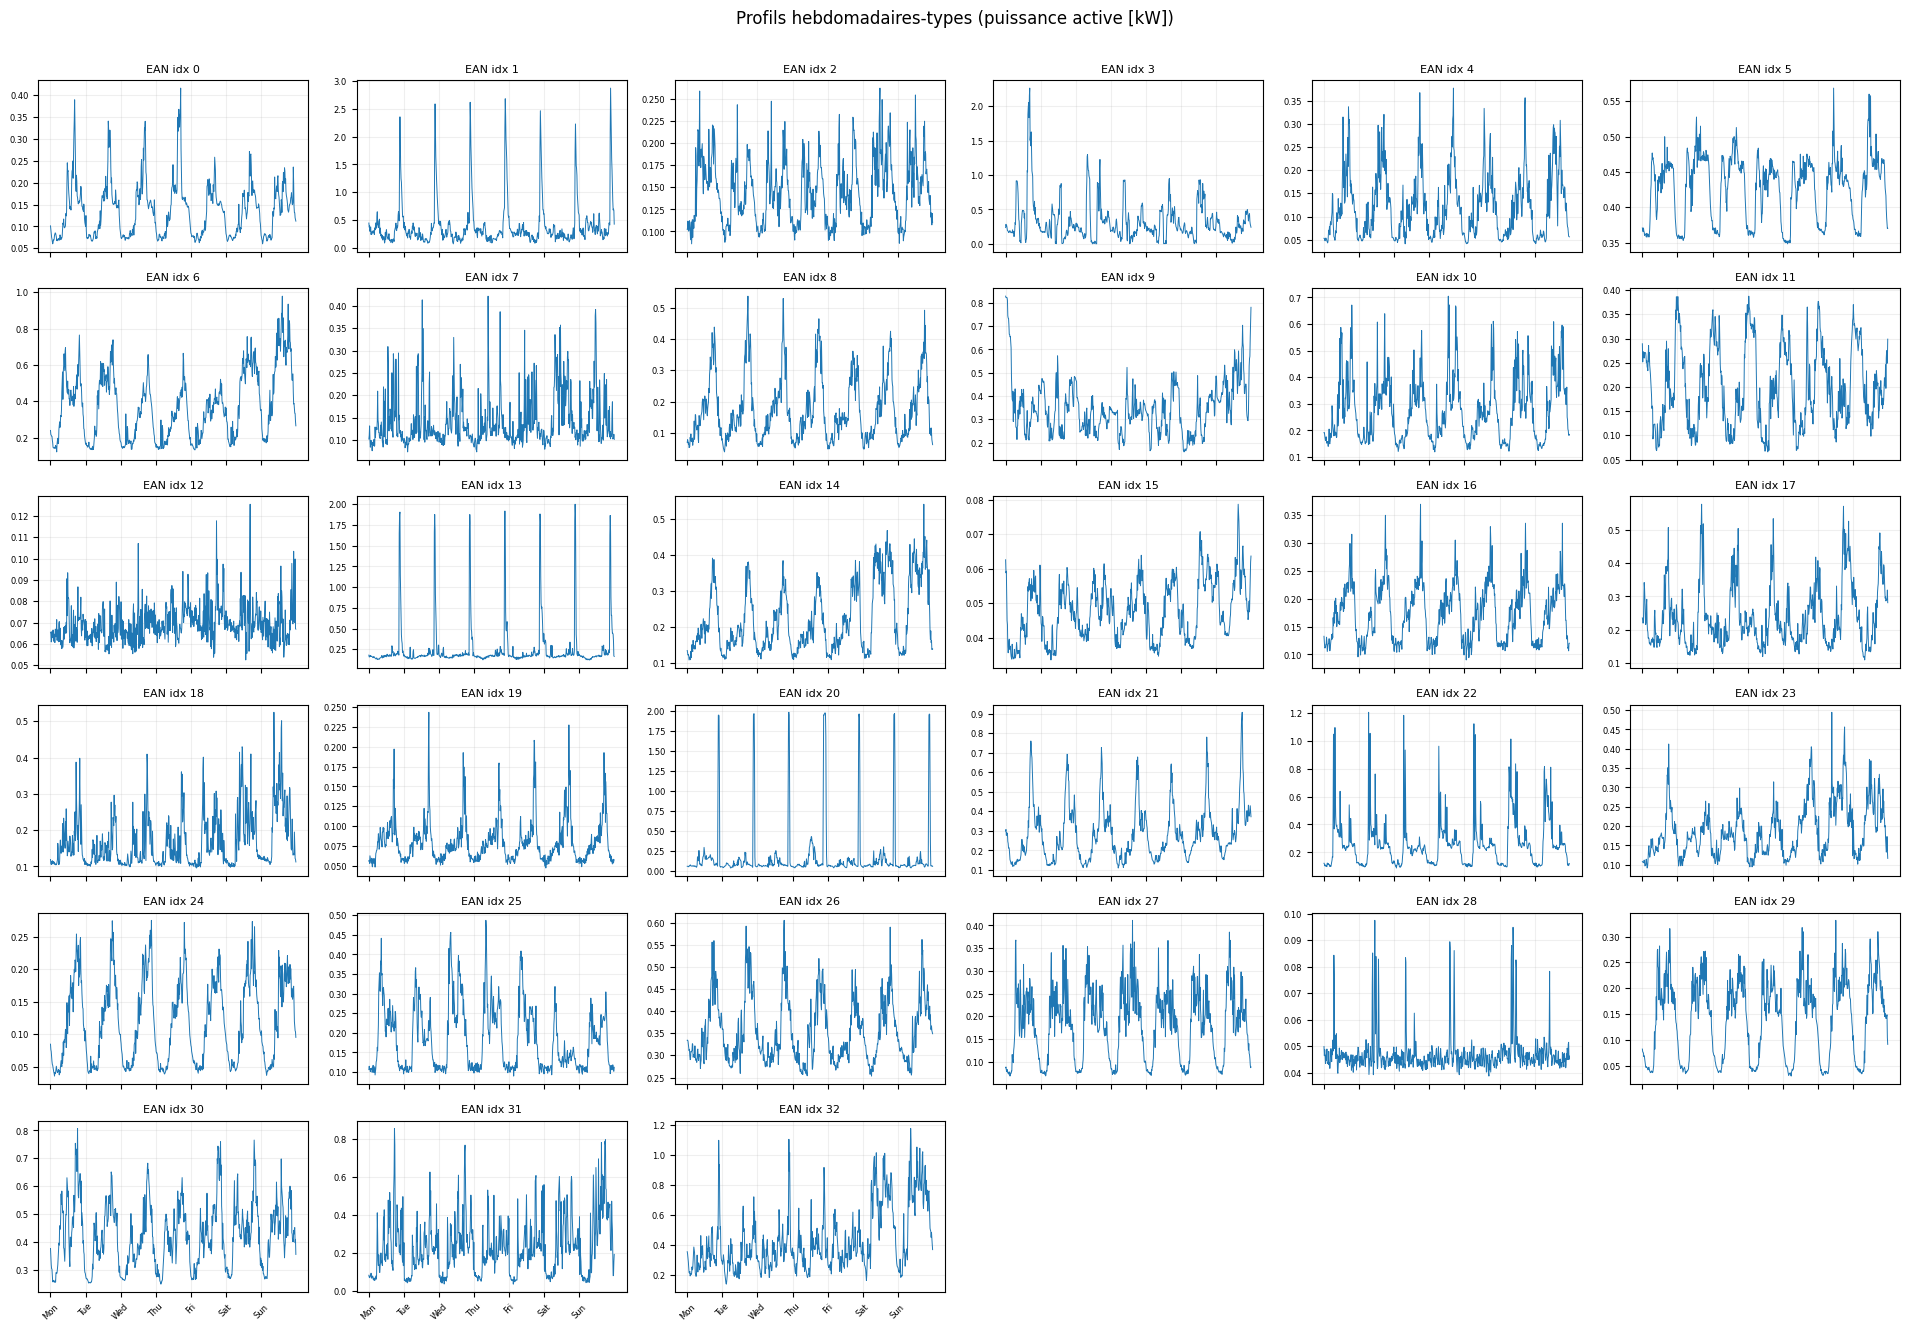

In [6]:
# --- Visualisation : grille des 33 profils hebdomadaires ---
import math

n = len(unique_eans)
ncols = int(math.ceil(math.sqrt(n)))
nrows = int(math.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.2, nrows * 2.2), sharex=True)
axes = axes.flatten()

day_ticks = [d * 96 for d in range(7)]  # début de chaque jour

for i in range(n):
    ax = axes[i]
    ax.plot(weekly_bank[i], linewidth=0.7)
    ax.set_title(f"EAN idx {i}", fontsize=8)
    ax.set_xticks(day_ticks)
    ax.set_xticklabels(days, fontsize=6, rotation=45)
    ax.tick_params(axis='y', labelsize=6)
    ax.grid(True, alpha=0.2)

for ax in axes[n:]:
    ax.axis('off')

fig.suptitle("Profils hebdomadaires-types (puissance active [kW])", y=1.005)
plt.tight_layout()
plt.show()

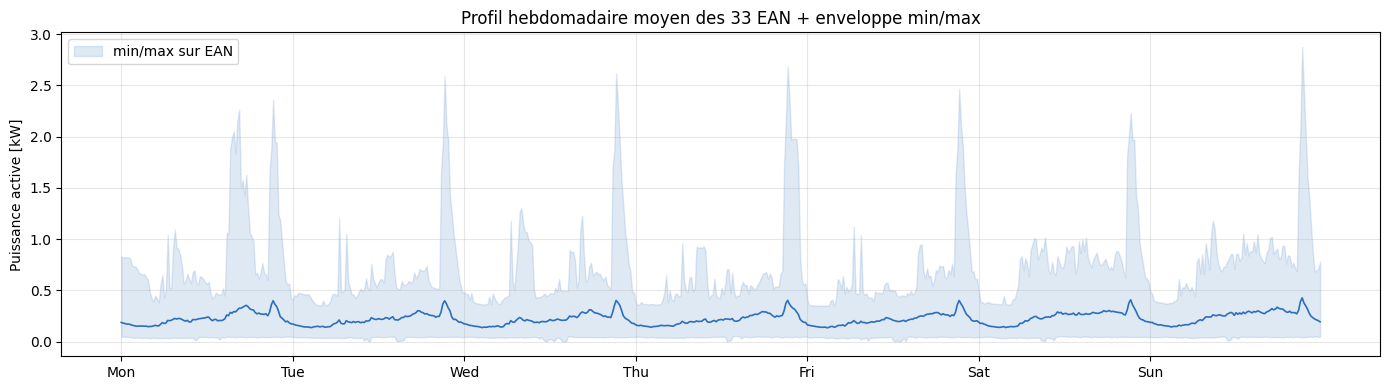

Pointe moyenne : 0.427 kW  (pas 661, Sun 21:15)
Creux moyen    : 0.135 kW  (pas 395, Fri 02:45)


In [7]:
# --- Profil hebdomadaire agrégé (moyenne sur les 33 EAN) ---
mean_week = weekly_bank.mean(axis=0)

plt.figure(figsize=(14, 4))
plt.plot(mean_week, linewidth=1.2, color='#2c6fbb')
plt.fill_between(range(N_PER_WEEK), weekly_bank.min(axis=0), weekly_bank.max(axis=0),
                 alpha=0.15, color='#2c6fbb', label='min/max sur EAN')
plt.xticks([d * 96 for d in range(7)], days)
plt.ylabel("Puissance active [kW]")
plt.title("Profil hebdomadaire moyen des 33 EAN + enveloppe min/max")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Pointe moyenne : {mean_week.max():.3f} kW  "
      f"(pas {mean_week.argmax()}, {time_index[mean_week.argmax()]})")
print(f"Creux moyen    : {mean_week.min():.3f} kW  "
      f"(pas {mean_week.argmin()}, {time_index[mean_week.argmin()]})")

In [8]:
# --- Génération de la banque de profils, étiquetés par rue source ---
N_BANK = 350                          # taille de banque (paramétrable, non contraignant)
rng = np.random.default_rng(42)       # graine fixe = banque déterministe

# Rue de chaque EAN (harmonisée sur la convention df_coords : espace, pas tiret)
ean_street = (df[['ean_anon', 'addressStreet']]
              .drop_duplicates()
              .set_index('ean_anon')['addressStreet'])
ean_street = ean_street.replace({"Avenue Joseph-Merlot": "Avenue Joseph Merlot"})
# rue indexée par position dans unique_eans
street_by_index = [ean_street[unique_eans[i]] for i in range(len(unique_eans))]

def make_profile(bank, rng):
    src = rng.integers(len(bank))                 # index EAN source (tirage uniforme -> option a)
    shift = rng.integers(-8, 9)                    # décalage ±2h (foisonnement)
    scale = rng.lognormal(mean=0, sigma=0.2)       # dispersion ~20%, > 0
    return np.roll(bank[src], shift) * scale, src, shift, round(scale, 4)

records = [make_profile(weekly_bank, rng) for _ in range(N_BANK)]
profile_bank = np.array([r[0] for r in records])   # (N_BANK, 672) en kW
src_ean    = [r[1] for r in records]
src_street = [street_by_index[r[1]] for r in records]   # <-- étiquette rue
src_shift  = [r[2] for r in records]
src_scale  = [r[3] for r in records]

print(f"Banque : {profile_bank.shape}")
print("Répartition par rue source :")
print(pd.Series(src_street).value_counts())

Banque : (350, 672)
Répartition par rue source :
Avenue Joseph Merlot    254
Rue Ernest Malvoz        63
Plateau du Bouhay        33
Name: count, dtype: int64


In [9]:
# --- load_profiles.csv : séries de charge (672 pas x N_BANK profils, MW) ---
load_profiles = pd.DataFrame(
    profile_bank.T / 1e3,                          # kW -> MW
    index=time_index,
    columns=[f"profile_{i}" for i in range(N_BANK)]
)
load_profiles.index.name = "week_step"
load_profiles.to_csv("data/load_profiles.csv")
print(f"Exporté : data/load_profiles.csv  ({load_profiles.shape[0]} pas x {load_profiles.shape[1]} profils, MW)")

Exporté : data/load_profiles.csv  (672 pas x 350 profils, MW)


In [10]:
# --- households.csv : métadonnées par profil (schéma du cadre + traçabilité) ---
households = pd.DataFrame({
    'profile_id':             range(N_BANK),
    'constellation':          pd.array([pd.NA]*N_BANK, dtype="Int64"),
    'building_type':          pd.array([pd.NA]*N_BANK, dtype="string"),
    'heat_pump':              pd.array([pd.NA]*N_BANK, dtype="boolean"),
    'electric_water_heating': pd.array([pd.NA]*N_BANK, dtype="boolean"),
    'electric_vehicle_type':  pd.array([pd.NA]*N_BANK, dtype="string"),
    'n_persons':              pd.array([pd.NA]*N_BANK, dtype="Int64"),
    'pv_system_size_kwp':     pd.array([pd.NA]*N_BANK, dtype="Float64"),
    'battery_size_kwh':       pd.array([pd.NA]*N_BANK, dtype="Float64"),
    # --- traçabilité de génération (hors schéma cadre, utile au debug) ---
    'source_street':          src_street,
    'source_ean_index':       src_ean,
})
households.to_csv("data/households.csv", index=False)
print(f"Exporté : data/households.csv  ({len(households)} ménages x {households.shape[1]} colonnes)")
households.head()

Exporté : data/households.csv  (350 ménages x 11 colonnes)


,profile_id,constellation,building_type,heat_pump,electric_water_heating,electric_vehicle_type,n_persons,pv_system_size_kwp,battery_size_kwh,source_street,source_ean_index
0,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Avenue Joseph Merlot,2
1,1,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Avenue Joseph Merlot,14
2,2,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Plateau du Bouhay,6
3,3,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Plateau du Bouhay,24
4,4,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Avenue Joseph Merlot,16


In [11]:
# --- Profils spécifiques des 4 bus MV "de passage" (power_flow.ipynb) ---
# Ces 4 bus ne sont pas des maisons : Paradis du Bouhay (maison de repos),
# Plantations (centre horticole), Omnisport BX (hall omnisport) et Groupe
# Scolaire (école) ont chacun un profil déterministe dédié. Exportés à part
# (data/mv_passage_profiles.csv), jamais mélangés à la banque de tirage
# aléatoire ci-dessus : ce sont des profils spécifiques par bus, pas des
# profils interchangeables piochables pour une maison orpheline.
#
# (!) Profils "purs" : consommation électrique uniquement (éclairage,
# informatique, ventilation, pompes, ascenseurs, cuisine électrique). Le
# chauffage des locaux et de l'eau sanitaire est exclu (autre vecteur
# énergétique), d'où des puissances nettement plus basses que la v1.

import random
random.seed(2026)  # reproductibilité, comme le reste du notebook

def get_mr_power(day_of_week, time_val):
    """Maison de repos - Éclairage, cuisine, ascenseurs, froid et auxiliaires.
    Chauffage des locaux et de l'eau exclu."""
    power = 28.0  # Talon de nuit épuré (froid alimentaire, veilles de sécurité)
    is_weekend = day_of_week >= 5
    if 6.5 <= time_val < 11.5:
        power = 42.0  # Réveil, éclairage des communs
    elif 11.5 <= time_val < 14.0:
        power = 58.0  # Pic de midi (cuisson et plonge électriques)
    elif 14.0 <= time_val < 17.5:
        power = 38.0  # Après-midi lissé
    elif 17.5 <= time_val < 20.0:
        power = 48.0  # Souper (réchauffage léger, éclairage de soirée)
    elif 20.0 <= time_val < 22.5:
        power = 34.0  # Coucher progressif
    if is_weekend:
        power *= 0.92
    return power * random.uniform(0.96, 1.04)

def get_ecole_power(day_of_week, time_val):
    """École - Éclairage, informatique, ventilation d'ambiance. Chauffage exclu."""
    is_weekend = day_of_week >= 5
    is_mercredi = day_of_week == 2
    if is_weekend:
        return 0.8 * random.uniform(0.95, 1.05)  # talon informatique/veilles
    if 7.5 <= time_val < 8.5:
        return 8.0 * random.uniform(0.95, 1.05)
    elif 8.5 <= time_val < 12.0:
        return 12.0 * random.uniform(0.95, 1.05)  # éclairage/PC
    elif 12.0 <= time_val < 13.5:
        return 9.0 * random.uniform(0.95, 1.05)   # pause midi
    elif 13.5 <= time_val < 16.0:
        return (1.5 if is_mercredi else 11.0) * random.uniform(0.95, 1.05)
    elif 16.0 <= time_val < 18.0:
        return 4.0 * random.uniform(0.95, 1.05)   # nettoyage/garderie
    else:
        return 1.2 * random.uniform(0.95, 1.05)   # nuit

def get_hall_sport_power(day_of_week, time_val):
    """Hall Omnisport - Éclairage des pistes et ventilation. Chauffage de l'eau
    des douches exclu."""
    is_weekend = day_of_week >= 5
    if not is_weekend:
        if 8.0 <= time_val < 16.0:
            return 5.0 * random.uniform(0.92, 1.08)   # écoles, éclairage partiel
        elif 16.0 <= time_val < 17.5:
            return 8.0 * random.uniform(0.95, 1.05)
        elif 17.5 <= time_val < 22.5:
            return 22.0 * random.uniform(0.95, 1.05)  # projecteurs pleins
        else:
            return 1.5 * random.uniform(0.95, 1.05)   # veille de nuit
    else:
        if 8.5 <= time_val < 21.5:
            return 18.0 * random.uniform(0.93, 1.07)  # journée de compétition
        else:
            return 1.8 * random.uniform(0.95, 1.05)

def get_horticole_power(day_of_week, time_val):
    """Centre Horticole - Éclairage horticole, pompes d'arrosage, ouvrants de
    serre. Chauffage des serres exclu."""
    is_weekend = day_of_week >= 5
    base_tech = 2.5 if is_weekend else 3.5  # circulateurs de base, hors chauffage
    if 7.5 <= time_val < 16.5:
        activity = 8.0 if not is_weekend else 1.5  # pompes d'arrosage, outillage
        return (base_tech + activity) * random.uniform(0.95, 1.05)
    else:
        return base_tech * random.uniform(0.95, 1.05)

mv_passage_profiles_kw = {
    "Paradis du Bouhay": [], "Plantations": [], "Omnisport BX": [], "Groupe Scolaire": [],
}
for step in range(N_PER_WEEK):
    dow = step // 96
    time_val = (step % 96) * 15 / 60.0
    mv_passage_profiles_kw["Paradis du Bouhay"].append(get_mr_power(dow, time_val))
    mv_passage_profiles_kw["Groupe Scolaire"].append(get_ecole_power(dow, time_val))
    mv_passage_profiles_kw["Omnisport BX"].append(get_hall_sport_power(dow, time_val))
    mv_passage_profiles_kw["Plantations"].append(get_horticole_power(dow, time_val))

mv_passage_profiles = pd.DataFrame(mv_passage_profiles_kw, index=time_index) / 1000  # kW -> MW
mv_passage_profiles.index.name = "week_step"
mv_passage_profiles.to_csv("data/mv_passage_profiles.csv")
print(f"Exporté : data/mv_passage_profiles.csv  ({mv_passage_profiles.shape[0]} pas x {mv_passage_profiles.shape[1]} profils, MW)")
mv_passage_profiles.describe()

Exporté : data/mv_passage_profiles.csv  (672 pas x 4 profils, MW)


,Paradis du Bouhay,Plantations,Omnisport BX,Groupe Scolaire
count,672.000000,672.000000,672.000000,672.000000
mean,0.037327,0.005515,0.008275,0.003508
std,0.009488,0.003645,0.008022,0.004126
min,0.024824,0.002376,0.001426,0.000761
25%,0.028187,0.003382,0.001561,0.000828
50%,0.036781,0.003579,0.004819,0.001203
75%,0.042601,0.010996,0.017651,0.004148
max,0.060252,0.012068,0.023088,0.012581
